In [1]:
print('In the name of Allah')

In the name of Allah


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.datasets import load_wine

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV

1. Iris Flower Classification using KNN

Dataset: Iris Dataset (UCI / Kaggle)

Dataset Link:

https://www.kaggle.com/datasets/uciml/iris

Tasks:

Load the dataset using Pandas.

Separate features and target.

Split the data into training and testing sets.

Train a KNN classifier with K=3.

Predict the test set labels.

Calculate the accuracy score.

Display the Confusion Matrix.

Generate the Classification Report.


In [3]:
df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df.isnull().sum()

,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


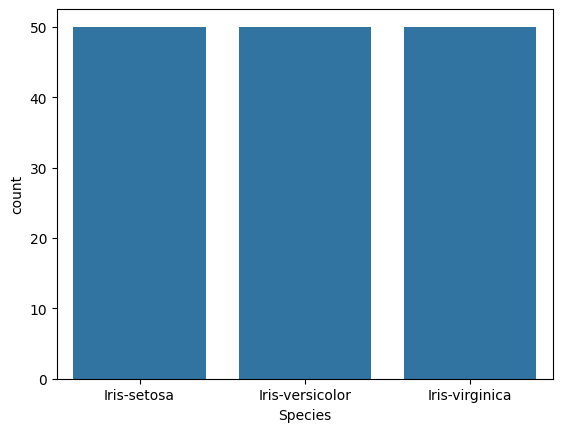

In [5]:
sns.countplot(data = df, x = 'Species')

plt.show()

In [6]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [8]:
df['Species'].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [9]:
df = df.drop('Id', axis = 1)

In [10]:
X = df.drop('Species', axis = 1)
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

In [11]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 120 entries, 8 to 3
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  120 non-null    float64
 1   SepalWidthCm   120 non-null    float64
 2   PetalLengthCm  120 non-null    float64
 3   PetalWidthCm   120 non-null    float64
dtypes: float64(4)
memory usage: 4.7 KB


In [12]:
X_train.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,120.000000,120.000000,120.000000,120.000000
mean,5.841667,3.044167,3.770833,1.204167
std,0.840926,0.445669,1.767417,0.763825
min,4.300000,2.000000,1.100000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.750000,3.000000,4.250000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [13]:
knn_model = Pipeline(
    steps = [
        ( 'scaler', StandardScaler() ),
        ( 'model', KNeighborsClassifier(n_neighbors = 3) )
    ]
)

knn_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier(n_neighbors=3))])

In [14]:
y_pred = knn_model.predict(X_test)

y_pred[:10]

array(['Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa', 'Iris-versicolor', 'Iris-setosa',
       'Iris-setosa', 'Iris-virginica', 'Iris-versicolor'], dtype=object)

In [15]:
accuracy = accuracy_score( y_test, y_pred )

print(f'Accuracy : {round(accuracy, 4)}')

Accuracy : 0.9333


In [16]:
conf_mat = confusion_matrix(y_test, y_pred)

conf_mat

array([[10,  0,  0],
       [ 0, 10,  0],
       [ 0,  2,  8]])

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=knn_model.classes_)
cm_df = pd.DataFrame(cm, index=knn_model.classes_, columns=knn_model.classes_)
cm_df

,Iris-setosa,Iris-versicolor,Iris-virginica
Iris-setosa,10,0,0
Iris-versicolor,0,10,0
Iris-virginica,0,2,8


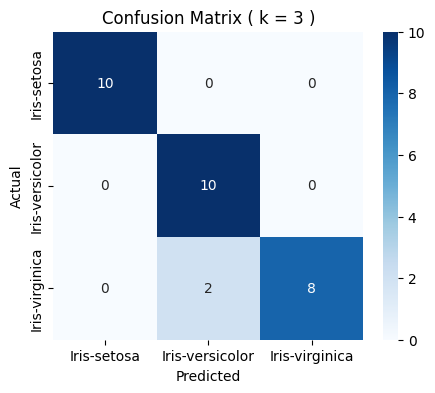

In [18]:
plt.figure(figsize = (5, 4))

sns.heatmap( cm_df, annot = True, fmt = 'd', cmap = 'Blues' )
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix ( k = 3 )')
plt.show()

In [19]:
print( classification_report(y_test, y_pred) )

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



2. GridSearchCV for Customer Segmentation Prediction

Dataset: Customer Personality Analysis

Dataset Link:

https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

Tasks:

Create a customer response prediction problem using the Response column.

Handle missing values.

Scale the numerical features.

Use GridSearchCV to tune:

n_neighbors

metric

weights

Report the best parameters.

Compare tuned KNN with default KNN.

Evaluate using:

Accuracy

Precision

Recall

F1-score


In [20]:
df = pd.read_csv('marketing_campaign.csv', sep = '\t')

df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [22]:
df['Response'].value_counts(normalize = True)

,proportion
Response,
0,0.850893
1,0.149107


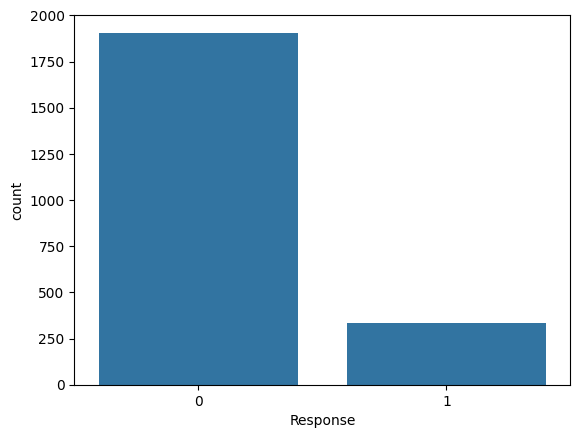

In [23]:
sns.countplot(data = df, x = 'Response')

plt.show()

Only about 15% of customers responded to the last campaign, so the classes are
imbalanced — accuracy alone will be a misleading metric here, which is why precision, recall
and F1 are reported alongside it below.

In [24]:
df.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [25]:
df['Income'].describe()

,Income
count,2216.000000
mean,52247.251354
std,25173.076661
min,1730.000000
25%,35303.000000
50%,51381.500000
75%,68522.000000
max,666666.000000


In [26]:
# Feature Engineering

df['Age'] = 2014 - df['Year_Birth']

df['Dt_Customer'] = pd.to_datetime( df['Dt_Customer'], format = '%d-%m-%Y' )

df['Customer_For'] = ( df['Dt_Customer'].max() - df['Dt_Customer'] ).dt.days

df['Total_Child'] = df['Kidhome'] + df['Teenhome']

mnt_cols = [ 'MntWines', 'MntFruits', 'MntMeatProducts',
            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds' ]

df['Total_Spending'] = df[mnt_cols].sum(axis = 1)


purchase_cols = [ 'NumDealsPurchases', 'NumWebPurchases',
                  'NumCatalogPurchases', 'NumStorePurchases' ]

df['Total_Purchases'] = df[purchase_cols].sum(axis = 1)

df[['Age', 'Customer_For', 'Total_Child', 'Total_Spending', 'Total_Purchases']].describe()


,Age,Customer_For,Total_Child,Total_Spending,Total_Purchases
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,45.194196,353.582143,0.950446,605.798214,14.862054
std,11.984069,202.122512,0.751803,602.249288,7.677173
min,18.000000,0.000000,0.000000,5.000000,0.000000
25%,37.000000,180.750000,0.000000,68.750000,8.000000
50%,44.000000,355.500000,1.000000,396.000000,15.000000
75%,55.000000,529.000000,1.000000,1045.500000,21.000000
max,121.000000,699.000000,3.000000,2525.000000,44.000000


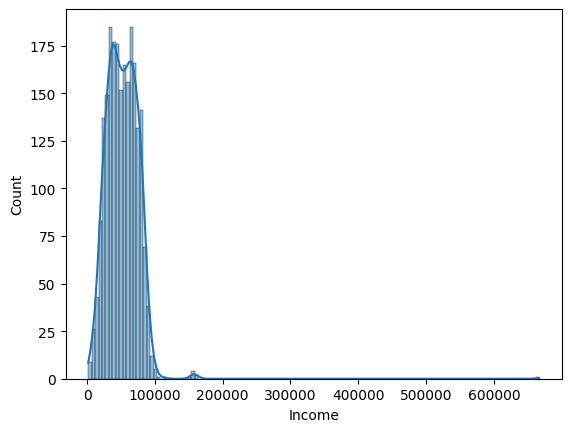

In [27]:
sns.histplot(data = df, x = 'Income', kde = True)

plt.show()

In [28]:
df['Income'] = df['Income'].fillna( df['Income'].median() )

df['Income'].isnull().sum()

np.int64(0)

In [29]:
df = df[df['Age'] < 100]

df = df[df['Income'] < 200000]

df.shape

(2236, 34)

In [30]:
# Feature Engineering on Categorical Columns

df['Education'].unique()
df['Education'] = df['Education'].replace( {'2n Cycle' : 'Master'} )

df['Marital_Status'].unique()

df['Marital_Status'] = df['Marital_Status'].replace(
    {'Alone' : 'Single', 'Absurd' : 'Single', 'YOLO' : 'Single'}
)

df['Marital_Status'].unique()

df = pd.get_dummies(df, columns=['Education', 'Marital_Status'], drop_first=True)

df = df.drop( ['ID', 'Year_Birth', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue'], axis = 1 )

In [31]:
df.shape

X = df.drop('Response', axis = 1)
y = df['Response']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

In [32]:
default_knn = Pipeline(
    steps = [
        ( 'scaler', StandardScaler() ),
        ( 'model', KNeighborsClassifier() )
    ]
)

default_knn.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])

In [33]:
y_pred = default_knn.predict(X_test)

default_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
}
default_metrics

{'Accuracy': 0.8705357142857143,
 'Precision': 0.6363636363636364,
 'Recall': 0.31343283582089554,
 'F1-score': 0.42}

In [34]:
grid = {
    'knn__n_neighbors' : range(1, 30),
    'knn__weights' : ['uniform', 'distance'],
    'knn__p' : [1, 2]
}

pipe = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

grid_search = GridSearchCV(
    estimator = pipe,
    param_grid = grid,
    cv = 5
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             param_grid={'knn__n_neighbors': range(1, 30), 'knn__p': [1, 2],
                         'knn__weights': ['uniform', 'distance']})

In [35]:
best_knn = grid_search.best_estimator_
y_pred_tuned = best_knn.predict(X_test)

tuned_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned),
    'Recall': recall_score(y_test, y_pred_tuned),
    'F1-score': f1_score(y_test, y_pred_tuned),
}

comparison = pd.DataFrame({'Default KNN': default_metrics, 'Tuned KNN (GridSearchCV)': tuned_metrics})
comparison.round(4)

,Default KNN,Tuned KNN (GridSearchCV)
Accuracy,0.8705,0.8839
Precision,0.6364,0.7143
Recall,0.3134,0.3731
F1-score,0.4200,0.4902


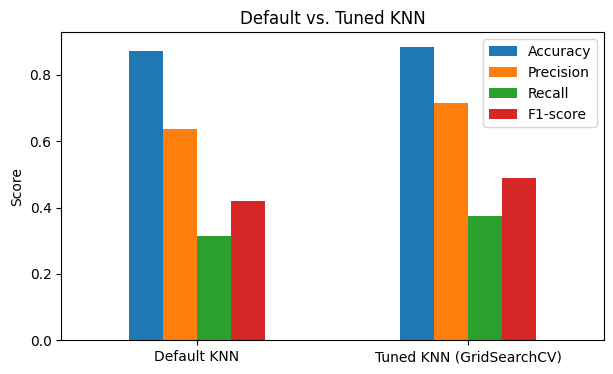

In [36]:
comparison.T.plot(kind='bar', figsize=(7, 4))
plt.title('Default vs. Tuned KNN')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend()
plt.show()

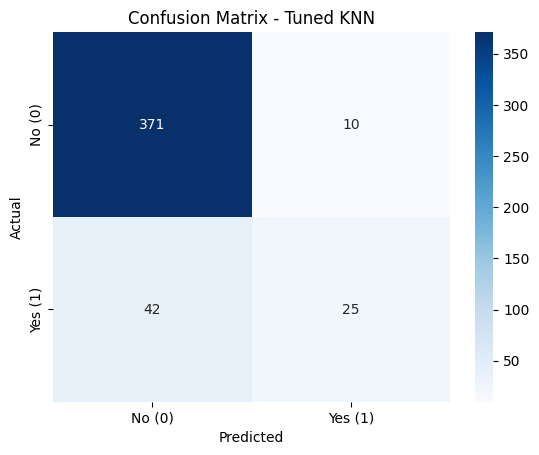

In [37]:
cm = confusion_matrix(y_test, y_pred_tuned)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No (0)', 'Yes (1)'], yticklabels=['No (0)', 'Yes (1)'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Tuned KNN')
plt.show()

In [38]:
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.90      0.97      0.93       381
           1       0.71      0.37      0.49        67

    accuracy                           0.88       448
   macro avg       0.81      0.67      0.71       448
weighted avg       0.87      0.88      0.87       448



## Summary

* GridSearchCV improves the F1-score for the minority ("will respond") class over the default
  KNN, mainly by switching from uniform to distance-based weighting and adjusting `n_neighbors`.
* Even after tuning, recall for the responder class stays modest. This is expected: the
  `Response` classes are imbalanced (about 85% / 15%), and KNN has no built-in mechanism for
  class imbalance, so it tends to favor the majority class. Accuracy alone (~88%) looks strong
  but hides this weakness, which is exactly why precision, recall, and F1 were tracked for the
  positive class.

# Optional

Credit Card Default Prediction

Dataset: Default of Credit Card Clients
Dataset Link:

https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset

Tasks:

Predict whether a client will default.

Check for class imbalance.

Standardize the features.

Train KNN with multiple K values.

Evaluate using:

Accuracy

Precision

Recall

F1-score

Determine whether accuracy alone is sufficient for this problem.


In [39]:
df = pd.read_csv('UCI_Credit_Card.csv')

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [41]:
df.shape

(30000, 25)

In [42]:
df = df.drop('ID', axis = 1)

In [43]:
df.isnull().sum()

,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0
PAY_5,0


In [44]:
df = df.rename(columns={'default.payment.next.month': 'default', 'PAY_0': 'PAY_1'})

df['default'].value_counts()

,count
default,
0,23364
1,6636


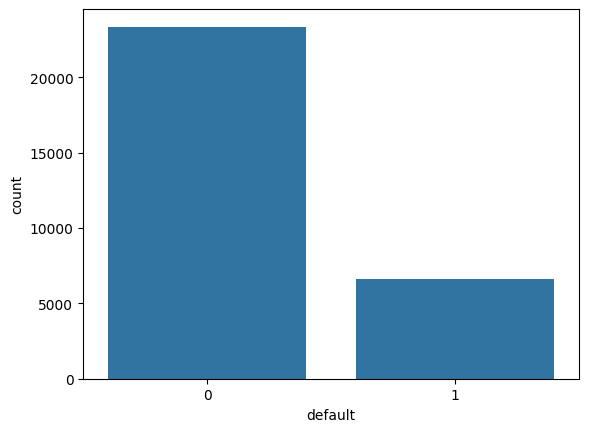

In [45]:
sns.countplot(data = df, x = 'default')

plt.show()

In [46]:
X = df.drop('default', axis = 1)

y = df['default']

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42, stratify = y )

In [47]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((24000, 23), (6000, 23), (24000,), (6000,))

In [48]:
knn_model = Pipeline(
    steps = [
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier())
    ]
)

knn_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])

In [49]:
y_pred = knn_model.predict(X_test)

y_pred

array([0, 0, 0, ..., 0, 0, 0])

In [50]:
accuracy = accuracy_score(y_test, y_pred)

accuracy

0.7928333333333333

In [51]:
conf_mat = confusion_matrix(y_test, y_pred)

conf_mat

array([[4284,  389],
       [ 854,  473]])

In [52]:
print( classification_report(y_test, y_pred) )

              precision    recall  f1-score   support

           0       0.83      0.92      0.87      4673
           1       0.55      0.36      0.43      1327

    accuracy                           0.79      6000
   macro avg       0.69      0.64      0.65      6000
weighted avg       0.77      0.79      0.78      6000



In [53]:
performance = []
acc = []

for k in range( 5, 30 ) :

  # if k % 2 != 0 and k % 3 != 0 :
  knn_model = Pipeline(
    steps = [
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors = k, metric = 'minkowski', p = 2 ))
    ]
    )

  knn_model.fit(X_train, y_train)

  y_pred = knn_model.predict(X_test)

  accuracy = round(accuracy_score(y_test, y_pred), 4)

  precision = round(precision_score(y_test, y_pred, average = 'weighted'), 4)
  recall = round(recall_score(y_test, y_pred, average = 'weighted'), 4)
  f1 = round(f1_score(y_test, y_pred, average = 'weighted'), 4)
  acc.append(accuracy)

  performance.append( (k, (accuracy, precision, recall, f1)) )

In [54]:
print(performance)

[(5, (0.7928, 0.7707, 0.7928, 0.7757)), (6, (0.8037, 0.7795, 0.8037, 0.7735)), (7, (0.8003, 0.7777, 0.8003, 0.7803)), (8, (0.8045, 0.7808, 0.8045, 0.7744)), (9, (0.8057, 0.7841, 0.8057, 0.785)), (10, (0.8085, 0.7868, 0.8085, 0.7803)), (11, (0.8093, 0.7888, 0.8093, 0.7885)), (12, (0.8078, 0.7858, 0.8078, 0.7804)), (13, (0.8072, 0.7857, 0.8072, 0.7854)), (14, (0.8075, 0.7853, 0.8075, 0.7808)), (15, (0.8065, 0.7845, 0.8065, 0.7837)), (16, (0.8078, 0.7858, 0.8078, 0.7806)), (17, (0.8085, 0.7872, 0.8085, 0.7855)), (18, (0.8088, 0.7873, 0.8088, 0.7831)), (19, (0.809, 0.7878, 0.809, 0.7857)), (20, (0.8085, 0.7868, 0.8085, 0.782)), (21, (0.8087, 0.7873, 0.8087, 0.7851)), (22, (0.808, 0.786, 0.808, 0.7812)), (23, (0.8093, 0.7881, 0.8093, 0.7851)), (24, (0.809, 0.7875, 0.809, 0.7826)), (25, (0.8078, 0.786, 0.8078, 0.7836)), (26, (0.808, 0.7861, 0.808, 0.7817)), (27, (0.8075, 0.7855, 0.8075, 0.7826)), (28, (0.8065, 0.7839, 0.8065, 0.7797)), (29, (0.8082, 0.7864, 0.8082, 0.7832))]


In [55]:
print( classification_report(y_test, y_pred) )

              precision    recall  f1-score   support

           0       0.83      0.95      0.88      4673
           1       0.63      0.32      0.43      1327

    accuracy                           0.81      6000
   macro avg       0.73      0.63      0.66      6000
weighted avg       0.79      0.81      0.78      6000



## Is accuracy alone sufficient for this problem?

No. Because roughly 78% of clients do not default, a trivial model that always predicts
"no default" would reach about 78% accuracy without ever identifying a single defaulter — which
is exactly the business outcome a bank wants to avoid. The table above shows accuracy staying
fairly flat (~80%) across K while **recall for the default class stays around 0.33–0.45**,
meaning KNN misses more than half of the actual defaulters. For a credit-risk problem like this,
**recall and F1-score for the default class (and ideally precision-recall trade-offs / ROC-AUC)
matter far more than overall accuracy**, since the cost of missing a defaulter is usually much
higher than the cost of a false alarm.

Letter Recognition Challenge

Dataset: Letter Recognition Dataset

Dataset Link:

https://www.kaggle.com/datasets/nishan192/letter-recognition-uci

Tasks:

Predict English alphabet letters (26 classes).

Standardize the features.

Build a baseline KNN classifier.

Use GridSearchCV to tune:

n_neighbors = [3, 5, 7, 9, 11, 15]

metric = ['euclidean', 'manhattan']

weights = ['uniform', 'distance']

Evaluate the final model using:

Accuracy

Confusion Matrix

Classification Report

Identify the letters that are most frequently misclassified and explain possible reasons.


In [56]:
df = pd.read_csv('letter-recognition.csv')

df.head()

,letter,xbox,ybox,width,height,onpix,xbar,ybar,x2bar,y2bar,xybar,x2ybar,xy2bar,xedge,xedgey,yedge,yedgex
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   letter  20000 non-null  object
 1   xbox    20000 non-null  int64 
 2   ybox    20000 non-null  int64 
 3   width   20000 non-null  int64 
 4   height  20000 non-null  int64 
 5   onpix   20000 non-null  int64 
 6   xbar    20000 non-null  int64 
 7   ybar    20000 non-null  int64 
 8   x2bar   20000 non-null  int64 
 9   y2bar   20000 non-null  int64 
 10  xybar   20000 non-null  int64 
 11  x2ybar  20000 non-null  int64 
 12  xy2bar  20000 non-null  int64 
 13  xedge   20000 non-null  int64 
 14  xedgey  20000 non-null  int64 
 15  yedge   20000 non-null  int64 
 16  yedgex  20000 non-null  int64 
dtypes: int64(16), object(1)
memory usage: 2.6+ MB


In [58]:
df.shape

(20000, 17)

In [59]:
df['letter'].value_counts().sort_index()

,count
letter,
A,789
B,766
C,736
D,805
E,768
F,775
G,773
H,734
I,755


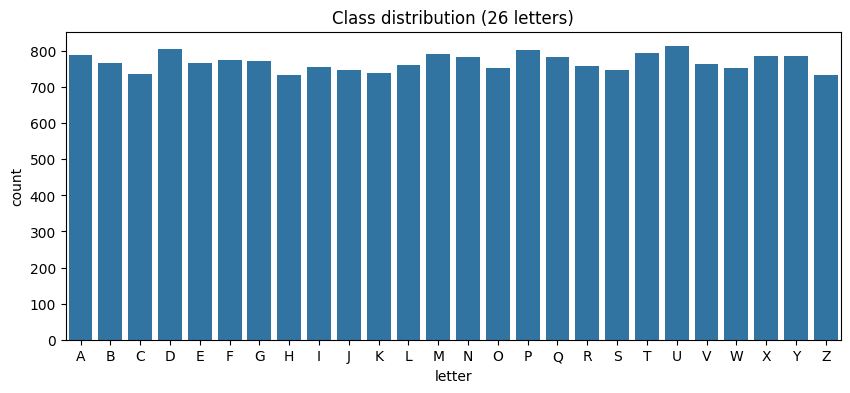

In [60]:
plt.figure(figsize=(10, 4))

sns.countplot(data=df, x='letter', order=sorted(df['letter'].unique()))
plt.title('Class distribution (26 letters)')
plt.show()

In [61]:
X = df.drop('letter', axis=1)
y = df['letter']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train.shape, X_test.shape

((16000, 16), (4000, 16))

In [62]:
baseline_knn = Pipeline(
    steps = [
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier())
    ]
)

baseline_knn.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

In [63]:
grid = {
    'knn__n_neighbors' : [3, 5, 7, 9, 11, 15],
    'knn__metric' : ['euclidean', 'manhattan'],
    'knn__weights' : ['uniform', 'distance']
}

grid_search = GridSearchCV(
    estimator = baseline_knn,
    param_grid = grid,
    cv = 5
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             param_grid={'knn__metric': ['euclidean', 'manhattan'],
                         'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
                         'knn__weights': ['uniform', 'distance']})

In [64]:
grid_search.best_estimator_

Pipeline(steps=[('scaler', StandardScaler()),
                ('knn',
                 KNeighborsClassifier(metric='manhattan', weights='distance'))])

In [65]:
model =  grid_search.best_estimator_

y_pred = model.predict(X_test)

In [66]:
accuracy = round(accuracy_score(y_test, y_pred), 4)

print(accuracy)

0.956


In [67]:
conf_mat = confusion_matrix(y_test, y_pred)

conf_mat

array([[156,   0,   1,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0],
       [  0, 144,   0,   0,   0,   0,   0,   3,   0,   0,   1,   0,   0,
          0,   0,   0,   0,   3,   1,   0,   1,   0,   0,   0,   0,   0],
       [  0,   0, 140,   0,   1,   0,   3,   0,   0,   0,   0,   0,   0,
          0,   1,   0,   1,   0,   0,   0,   0,   0,   1,   0,   0,   0],
       [  0,   0,   0, 159,   0,   0,   0,   2,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   3,   0, 145,   0,   1,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   2,   0,   3],
       [  0,   1,   0,   0,   1, 140,   0,   1,   0,   0,   0,   0,   0,
          2,   0,   5,   0,   0,   1,   4,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   1,   6,   0, 144,   0,   0,   0,   2,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   

In [68]:
print( classification_report(y_test, y_pred) )

              precision    recall  f1-score   support

           A       0.99      0.99      0.99       158
           B       0.94      0.94      0.94       153
           C       0.95      0.95      0.95       147
           D       0.91      0.99      0.95       161
           E       0.92      0.94      0.93       154
           F       0.96      0.90      0.93       155
           G       0.95      0.93      0.94       155
           H       0.87      0.87      0.87       147
           I       0.97      0.93      0.95       151
           J       0.94      0.97      0.95       149
           K       0.92      0.92      0.92       148
           L       0.99      0.98      0.99       152
           M       0.99      0.96      0.97       158
           N       0.96      0.92      0.94       157
           O       0.94      0.95      0.94       150
           P       0.97      0.96      0.96       161
           Q       0.96      0.98      0.97       157
           R       0.95    

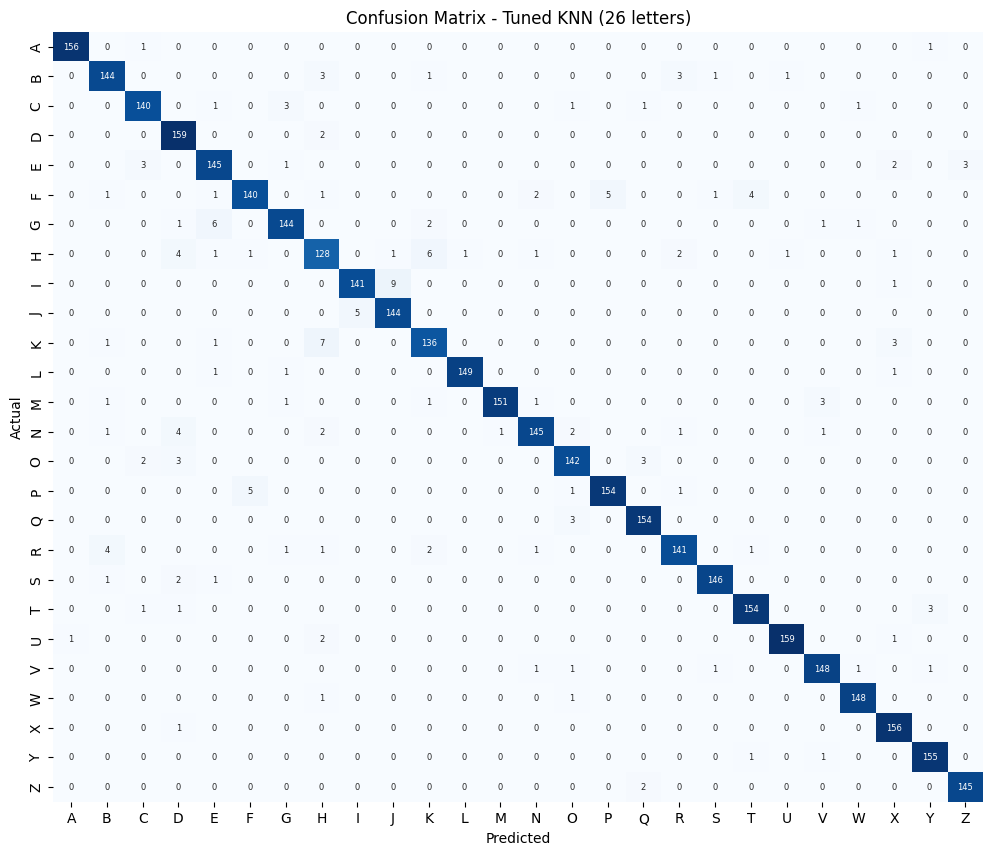

In [69]:
labels = sorted(y.unique())

cm = confusion_matrix(y_test, y_pred, labels=labels)

cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(12, 10))

sns.heatmap(cm_df,
            annot=True,
            fmt='d',
            cmap='Blues',
            cbar=False,
            annot_kws={'size': 6}
            )

plt.title('Confusion Matrix - Tuned KNN (26 letters)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

In [70]:
pairs = []
for i, a in enumerate(labels):
    for j, b in enumerate(labels):
        if a != b and cm[i, j] > 0:
            pairs.append((a, b, cm[i, j]))

pairs_df = pd.DataFrame(pairs, columns=['True', 'Predicted', 'Count']).sort_values('Count', ascending=False)
pairs_df.head(15)

,True,Predicted,Count
39,I,J,9
44,K,H,7
25,G,E,6
33,H,K,6
41,J,I,5
21,F,P,5
64,P,F,5
29,H,D,4
55,N,D,4
68,R,B,4


### Why these letters get confused

The letters with the most errors (H, F, N, K, G, I/J, R, E, B, O) are exactly the ones whose
16 statistical features — box position, width/height, pixel density, edge counts — produce very
similar numeric signatures when several fonts are blended together:

* **I and J** differ mainly by the small hook/dot at the bottom of J, a tiny detail that barely
  changes the *global* statistical moments (mean position, variance, edge counts) used as
  features here, so they look almost identical numerically.
* **H, K, and R** all share a vertical stroke with one or two diagonal/angled strokes
  branching off it; the overall bounding box, pixel density, and edge-count statistics end up
  very close together even though a human eye distinguishes them easily from the exact stroke
  angle.
* **F and P** (and F and T) share a vertical stem with a horizontal/rounded element near the
  top, again giving similar box and density statistics.
* **G, C, and E** share a similar curved/open shape on one side.

In short, KNN here doesn't see pixel images directly — it sees 16 aggregated statistical
descriptors. Letters that are visually distinct can still map to nearby points in that
16-dimensional feature space if their *aggregate* shape statistics (not their fine local
strokes) happen to be similar, and that's where most of the confusion comes from. A model that
used the raw pixel grid (e.g., a CNN) would likely resolve many of these confusions because it
can exploit the local stroke patterns that this hand-engineered feature set partly discards.